In [1]:
## SOMMAIRE DU NOTEBOOK
#
# ETAPE 0 - Chargement des données
#
# ETAPE 1 - Explorez le jeu de données
# Detail des colonnes
# Recherche de doublons
# Liste des produits
# Tableau récapitulatif statistique
# Pourcentage des ventes par produit et par an
#
# ETAPE 2 - Analysez l'évolution des volumes commandés sur le top 5 des références produits
# Sélection du top 5 des produits
# Identification des données aberrantes avec la méthode z-score
# Identification des données aberrantes avec la méthode des écarts inerquartiles
# Graphique en barre des ventes annuelles par produit
# Graphique en lignes des ventes journalières par produit
# Calcul évolution des ventes des produits par régression linéaire
# Calcul évolution des ventes des produits par taux d'évolution
#
# ETAPE 3 - Analysez comparativement les volumes commandés pour les différents produits du Top 5
# Graphique en ligne comparatif des ventes annuelles par produit
# Tableau des pourcentages de ventes par mois par produit et rangs mensuels
# Graphique en ligne comparatif des ventes mensuelles par produit
#
# ETAPE 4 - proposez une répartition optimale de stock dans l'entrepôt  
# Graphique en ligne comparatif des ventes mensuelles moyennes par produit et par identifiant mois
# Carte thermique des rangs mensuels des ventes par mois et par produit
# Matrice de corrélation des ventes des produits du top 5
# Graphiques de distribution des données de ventes des produits du top 5
# Tests de normalité des séries statistiques de ventes
# Calculs de corrélation et représentations graphiques
#
# Recommandations d'améliorations
# Prévisions des ventes
#

In [2]:
##
## ETAPE 0 - Chargement des données
##

In [3]:
## chargement des librairies
import pandas as pd
import numpy as np
import datetime
import time
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro

In [4]:
## chemin du dataset
df_file = "Jeu+de+donneģes_P9_SCA.xlsx"

In [5]:
# chargement du dataset
df = pd.read_excel(df_file)
df

## le jeu de données comporte trois colonnes
## date : format us aaaa-mm-jj
## product : donnée qualitative : nom du produit
## sales : donnée quantitative : ventes en euros par jour et par produit

,date,product,sales
0,2017-01-01,tomate,121.629409
1,2017-01-02,tomate,118.254860
2,2017-01-03,tomate,115.894564
3,2017-01-04,tomate,112.591428
4,2017-01-05,tomate,105.016703
...,...,...,...
32860,2022-12-27,mangue,44.855785
32861,2022-12-28,mangue,39.626589
32862,2022-12-29,mangue,42.041256
32863,2022-12-30,mangue,43.909817


In [6]:
# selection de la période d'analyse - 4 dernières années 2019/2020/2021/2022
df = df[df['date'] >= '2019-01-01']
df['sales'] = df['sales'].round(2)
df = df.reset_index(drop=True)
#df

C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\635836236.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sales'] = df['sales'].round(2)


In [7]:
##
##
# ETAPE 1 - Explorez le jeu de données
# Detail des colonnes
# Recherche de doublons
# Liste des produits
# Tableau récapitulatif statistique
# Pourcentage des ventes par produit et par an
##
##

In [8]:
# affichage cinq premières lignes
df.head(5)

,date,product,sales
0,2019-01-01,tomate,128.89
1,2019-01-02,tomate,121.19
2,2019-01-03,tomate,129.49
3,2019-01-04,tomate,111.83
4,2019-01-05,tomate,121.21


In [9]:
# affichage cinq dernières lignes
df.tail(5)

,date,product,sales
21910,2022-12-27,mangue,44.86
21911,2022-12-28,mangue,39.63
21912,2022-12-29,mangue,42.04
21913,2022-12-30,mangue,43.91
21914,2022-12-31,mangue,44.58


In [10]:
## Données manquantes 
## le fichier n'a pas de données manquantes, il y a 21915 données sur chacune des trois colonnes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21915 entries, 0 to 21914
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     21915 non-null  datetime64[ns]
 1   product  21915 non-null  object        
 2   sales    21915 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 513.8+ KB


In [11]:
## tableau doublons
df_doublon = df
df_doublon['cc'] = df_doublon['date'].astype(str) +"-"+ df_doublon["product"].astype(str) +"-"+ df_doublon["sales"].astype(str)
df_doublon['nbcc'] = df_doublon.groupby('cc')['cc'].transform('count')

## identification des doublons
## il n'y a pas de lignes en doublon sur le fichier
print("- Nombre de doublons dans le fichier:",df_doublon.cc.duplicated().sum())

- Nombre de doublons dans le fichier: 0


In [12]:
# nombre de produits et liste des produits

product_number = df['product'].nunique()
product_list = df['product'].unique()

print("- Nombre de produits:",product_number)
print("- Liste des produits:",product_list)

- Nombre de produits: 15
- Liste des produits: ['tomate' 'pomme' 'banane' 'abricot' 'kiwi' 'pasteque' 'ananas' 'peche'
 'orange' 'melon' 'poire' 'clementine' 'cerise' 'pamplemousse' 'mangue']


In [13]:
# tableau croisé dynamnique des données de ventes produits
table_product = pd.pivot_table(df, values='sales', index='date', columns='product')
#table_product = table_product.rename_axis('date').rename_axis('index', axis=1)
table_product = table_product.reset_index()
table_product

product,date,abricot,ananas,banane,cerise,clementine,kiwi,mangue,melon,orange,pamplemousse,pasteque,peche,poire,pomme,tomate
0,2019-01-01,120.59,71.75,159.27,70.13,140.25,157.38,42.54,66.73,114.45,73.81,94.87,68.57,83.47,137.26,128.89
1,2019-01-02,107.68,152.40,76.60,69.80,113.01,148.23,42.29,63.10,119.54,62.96,69.89,73.48,82.99,144.48,121.19
2,2019-01-03,120.04,82.97,164.33,44.73,65.26,151.54,42.66,74.94,60.96,63.48,83.31,69.66,92.22,149.30,129.49
3,2019-01-04,94.92,119.20,170.72,44.84,74.18,171.65,44.97,72.72,88.61,47.99,70.25,64.54,65.30,141.97,111.83
4,2019-01-05,128.23,89.54,124.12,63.07,92.23,147.15,36.91,55.07,83.79,93.97,59.88,53.97,83.95,127.76,121.21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2022-12-27,105.86,120.86,131.17,69.45,139.57,146.75,44.86,64.88,118.61,77.99,76.63,70.50,67.61,149.24,148.34
1457,2022-12-28,88.64,97.61,89.22,59.71,126.92,118.88,39.63,73.57,99.06,56.84,91.25,102.74,95.04,133.36,146.87
1458,2022-12-29,76.24,128.89,133.51,71.78,46.20,146.80,42.04,76.08,144.00,60.43,79.20,77.07,107.70,138.96,129.02
1459,2022-12-30,100.61,87.33,127.39,63.19,49.94,182.89,43.91,62.60,98.52,69.17,86.70,70.70,69.31,164.89,136.79


In [14]:
# Description des distributions statistiques
table_product_describe = table_product.describe()
table_product_describe = table_product_describe.round(2)
table_product_describe = table_product_describe.drop('date', axis=1)
table_product_describe

product,abricot,ananas,banane,cerise,clementine,kiwi,mangue,melon,orange,pamplemousse,pasteque,peche,poire,pomme,tomate
count,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00,1461.00
mean,122.36,91.15,128.84,71.89,77.98,117.14,43.08,81.27,87.99,68.99,93.74,88.30,77.21,154.31,163.04
min,58.49,26.59,67.45,18.33,0.98,58.71,35.54,39.85,9.04,5.33,41.12,4.06,34.16,76.60,107.58
25%,103.76,75.70,115.29,57.88,62.25,99.82,41.31,68.92,70.75,54.23,80.66,69.26,67.74,138.86,140.48
50%,120.63,89.99,129.24,70.74,77.34,115.20,43.09,80.66,87.18,68.51,92.32,85.65,77.40,154.09,162.56
75%,139.25,105.80,142.70,84.78,93.40,133.69,44.87,93.27,104.90,83.13,105.83,104.81,86.90,170.42,183.27
max,199.86,173.13,187.62,141.55,150.91,183.46,51.55,129.21,178.43,147.42,155.48,198.67,120.46,224.91,228.91
std,24.33,22.20,19.61,20.56,22.86,23.16,2.56,15.86,25.69,21.50,17.35,27.65,14.08,23.61,25.13


In [15]:
# transformation et modification des données pour les analyses graphiques et statistiques
df_year = df
df_year['year'] = df_year["date"].dt.year
df_year['quarter'] = df_year["date"].dt.quarter
df_year['month'] = df_year["date"].dt.month
df_year['year_quarter'] = df_year['year'].astype(str) +"-"+ df_year["quarter"].astype(str)
df_year['year_month'] = df_year['year'].astype(str) +"-"+ df_year["month"].astype(str)
df_year['sales_year'] = df_year.groupby(['product','year'])['sales'].transform('sum')
df_year['sales_year_mean'] = df_year.groupby(['product','year'])['sales'].transform('mean')
df_year['sales_quarter'] = df_year.groupby(['product','year_quarter'])['sales'].transform('sum')
df_year['sales_month'] = df_year.groupby(['product','year_month'])['sales'].transform('sum')
df_year['rolling_sales_14'] = df_year['sales'].rolling(14).mean()
df_year = df_year.round(0)
#df_year

In [16]:
# tableau croisé dynamique des ventes totales par produit et année

table_year = pd.pivot_table(df_year, values='sales', index='product', columns='year', aggfunc='sum')
#table_year = table_year.rename_axis('index').rename_axis('index', axis=1)
table_year = table_year.reset_index()
table_year = table_year.round(0)
#table_year

In [17]:
# tableaux des ventes totales par année et produit et part des volumes de vente par année

table_year_pct = table_year
table_year_pct['%_2019'] = table_year_pct.iloc[:, 1] / table_year_pct.iloc[:, 1].sum()
table_year_pct['%_2020'] = table_year_pct.iloc[:, 2] / table_year_pct.iloc[:, 2].sum()
table_year_pct['%_2021'] = table_year_pct.iloc[:, 3] / table_year_pct.iloc[:, 3].sum()
table_year_pct['%_2022'] = table_year_pct.iloc[:, 4] / table_year_pct.iloc[:, 4].sum()
table_year_pct = table_year_pct.round(3)
table_year_pct

year,product,2019,2020,2021,2022,%_2019,%_2020,%_2021,%_2022
0,abricot,44898.0,44881.0,44589.0,44393.0,0.085,0.084,0.083,0.082
1,ananas,33595.0,32847.0,33118.0,33632.0,0.063,0.062,0.061,0.062
2,banane,46903.0,47496.0,46911.0,46951.0,0.089,0.089,0.087,0.087
3,cerise,26343.0,26594.0,25923.0,26180.0,0.050,0.050,0.048,0.048
4,clementine,27983.0,27950.0,28243.0,29748.0,0.053,0.052,0.052,0.055
5,kiwi,42441.0,42870.0,42864.0,42945.0,0.080,0.080,0.080,0.079
6,mangue,15702.0,15745.0,15790.0,15704.0,0.030,0.030,0.029,0.029
7,melon,29766.0,29384.0,29679.0,29909.0,0.056,0.055,0.055,0.055
8,orange,31737.0,31729.0,32662.0,32408.0,0.060,0.060,0.061,0.060
9,pamplemousse,24602.0,24397.0,26791.0,25020.0,0.046,0.046,0.050,0.046


In [18]:
###
###
# ETAPE 2 - Analysez l'évolution des volumes commandés sur le top 5 des références produits
# Sélection du top 5 des produits
# Identification des données aberrantes avec la méthode z-score
# Identification des données aberrantes avec la méthode des écarts inerquartiles
# Graphique en barre des ventes annuelles par produit
# Graphique en lignes des ventes journalières par produit
# Calcul évolution des ventes des produits par régression linéaire
# Calcul évolution des ventes des produits par taux d'évolution
###
###

In [19]:
# Identification et sélection du TOP 5 des produits

table_year_pct["rang_2019"] = table_year_pct['%_2019'].rank(ascending=False)
table_year_pct["rang_2020"] = table_year_pct['%_2020'].rank(ascending=False)
table_year_pct["rang_2021"] = table_year_pct['%_2021'].rank(ascending=False)
table_year_pct["rang_2022"] = table_year_pct['%_2022'].rank(ascending=False)
table_year_pct = table_year_pct.sort_values(by=['rang_2022'])
table_year_pct = table_year_pct[table_year_pct['rang_2022'] <= 5]
table_year_pct = table_year_pct.reset_index(drop=True)
table_year_pct

year,product,2019,2020,2021,2022,%_2019,%_2020,%_2021,%_2022,rang_2019,rang_2020,rang_2021,rang_2022
0,tomate,56582.0,58560.0,60400.0,62666.0,0.107,0.110,0.112,0.116,1.0,1.0,1.0,1.0
1,pomme,54462.0,55671.0,57579.0,57727.0,0.103,0.105,0.107,0.106,2.0,2.0,2.0,2.0
2,banane,46903.0,47496.0,46911.0,46951.0,0.089,0.089,0.087,0.087,3.0,3.0,3.0,3.0
3,abricot,44898.0,44881.0,44589.0,44393.0,0.085,0.084,0.083,0.082,4.0,4.0,4.0,4.0
4,kiwi,42441.0,42870.0,42864.0,42945.0,0.080,0.080,0.080,0.079,5.0,5.0,5.0,5.0


In [20]:
## liste des produits du TOP 5

list_product_top5 = table_year_pct['product'].tolist()
list_product_top5

['tomate', 'pomme', 'banane', 'abricot', 'kiwi']

In [21]:
table_product_top5 = table_product[['date','abricot','banane','kiwi','pomme','tomate']]
#table_product_top5

In [22]:
df_year_top5 = df_year[ df_year['product'].isin(list_product_top5)]
#df_year_top5

In [23]:
## identification par z-score des données abérrantes des ventes du Top 5

table_product_top5_zscore = table_product_top5
table_product_top5_zscore['abricotmean'] = table_product_top5_zscore["abricot"].mean()
table_product_top5_zscore['bananemean'] = table_product_top5_zscore["banane"].mean()
table_product_top5_zscore['kiwimean'] = table_product_top5_zscore["kiwi"].mean()
table_product_top5_zscore['pommemean'] = table_product_top5_zscore["pomme"].mean()
table_product_top5_zscore['tomatemean'] = table_product_top5_zscore["tomate"].mean()
table_product_top5_zscore['abricotstd'] = table_product_top5_zscore["abricot"].std()
table_product_top5_zscore['bananestd'] = table_product_top5_zscore["banane"].std()
table_product_top5_zscore['kiwistd'] = table_product_top5_zscore["kiwi"].std()
table_product_top5_zscore['pommestd'] = table_product_top5_zscore["pomme"].std()
table_product_top5_zscore['tomatestd'] = table_product_top5_zscore["tomate"].std()
table_product_top5_zscore["abricot_z_score"] = (table_product_top5_zscore["abricot"] - table_product_top5_zscore['abricotmean']) / table_product_top5_zscore['abricotstd']
table_product_top5_zscore["banane_z_score"] = (table_product_top5_zscore["banane"] - table_product_top5_zscore['bananemean']) / table_product_top5_zscore['bananestd']
table_product_top5_zscore["kiwi_z_score"] = (table_product_top5_zscore["kiwi"] - table_product_top5_zscore['kiwimean']) / table_product_top5_zscore['kiwistd']
table_product_top5_zscore["pomme_z_score"] = (table_product_top5_zscore["pomme"] - table_product_top5_zscore['pommemean']) / table_product_top5_zscore['pommestd']
table_product_top5_zscore["tomate_z_score"] = (table_product_top5_zscore["tomate"] - table_product_top5_zscore['tomatemean']) / table_product_top5_zscore['tomatestd']
table_product_top5_zscore["abricot_z_outliers"] = np.where( ((table_product_top5_zscore["abricot_z_score"] < -3) | (table_product_top5_zscore["abricot_z_score"] > 3)), 1,0) 
table_product_top5_zscore["banane_z_outliers"] = np.where( ((table_product_top5_zscore["banane_z_score"] < -3) | (table_product_top5_zscore["banane_z_score"] > 3)), 1,0) 
table_product_top5_zscore["kiwi_z_outliers"] = np.where( ((table_product_top5_zscore["kiwi_z_score"] < -3) | (table_product_top5_zscore["kiwi_z_score"] > 3)), 1,0) 
table_product_top5_zscore["pomme_z_outliers"] = np.where( ((table_product_top5_zscore["pomme_z_score"] < -3) | (table_product_top5_zscore["pomme_z_score"] > 3)), 1,0) 
table_product_top5_zscore["tomate_z_outliers"] = np.where( ((table_product_top5_zscore["tomate_z_score"] < -3) | (table_product_top5_zscore["tomate_z_score"] > 3)), 1,0) 

C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\3339352226.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  table_product_top5_zscore['abricotmean'] = table_product_top5_zscore["abricot"].mean()
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\3339352226.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  table_product_top5_zscore['bananemean'] = table_product_top5_zscore["banane"].mean()
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\3339352226.py:6: SettingWithCopyWarning: 
A value is trying to be set on 

In [24]:
## comptage du nombre outliers par produit
print("- Nombre de données aberrantes pour les données de ventes du produit abricot:",len(table_product_top5_zscore[table_product_top5_zscore['abricot_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit banane:",len(table_product_top5_zscore[table_product_top5_zscore['banane_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit kiwi:",len(table_product_top5_zscore[table_product_top5_zscore['kiwi_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit pomme:",len(table_product_top5_zscore[table_product_top5_zscore['pomme_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit tomate:",len(table_product_top5_zscore[table_product_top5_zscore['tomate_z_outliers']==1]))

- Nombre de données aberrantes pour les données de ventes du produit abricot: 3
- Nombre de données aberrantes pour les données de ventes du produit banane: 2
- Nombre de données aberrantes pour les données de ventes du produit kiwi: 0
- Nombre de données aberrantes pour les données de ventes du produit pomme: 1
- Nombre de données aberrantes pour les données de ventes du produit tomate: 0


In [25]:
## proportion du nombre outliers par produit
print("- Pourcentage de données aberrantes pour les données de ventes du produit abricot:", round(len(table_product_top5_zscore[table_product_top5_zscore['abricot_z_outliers']==1]) / len(table_product_top5_zscore),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit banane:", round(len(table_product_top5_zscore[table_product_top5_zscore['banane_z_outliers']==1]) / len(table_product_top5_zscore),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit kiwi:", round(len(table_product_top5_zscore[table_product_top5_zscore['kiwi_z_outliers']==1]) / len(table_product_top5_zscore),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit pomme:", round(len(table_product_top5_zscore[table_product_top5_zscore['pomme_z_outliers']==1]) / len(table_product_top5_zscore),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit tomate:", round(len(table_product_top5_zscore[table_product_top5_zscore['tomate_z_outliers']==1]) / len(table_product_top5_zscore),3) )

- Pourcentage de données aberrantes pour les données de ventes du produit abricot: 0.002
- Pourcentage de données aberrantes pour les données de ventes du produit banane: 0.001
- Pourcentage de données aberrantes pour les données de ventes du produit kiwi: 0.0
- Pourcentage de données aberrantes pour les données de ventes du produit pomme: 0.001
- Pourcentage de données aberrantes pour les données de ventes du produit tomate: 0.0


In [26]:
## il a y a très peu de données aberrantes dans les données de ventes en utilisant la méthode z-score

In [27]:
## identification par intervalle interquartile des données abérrantes des ventes du Top 5
table_product_top5_quantile = table_product_top5
table_product_top5_quantile['abricot_qt25'] = table_product_top5_quantile["abricot"].quantile(0.25)
table_product_top5_quantile['banane_qt25'] = table_product_top5_quantile["banane"].quantile(0.25)
table_product_top5_quantile['kiwi_qt25'] = table_product_top5_quantile["kiwi"].quantile(0.25)
table_product_top5_quantile['pomme_qt25'] = table_product_top5_quantile["pomme"].quantile(0.25)
table_product_top5_quantile['tomate_qt25'] = table_product_top5_quantile["tomate"].quantile(0.25)
table_product_top5_quantile['abricot_qt75'] = table_product_top5_quantile["abricot"].quantile(0.75)
table_product_top5_quantile['banane_qt75'] = table_product_top5_quantile["banane"].quantile(0.75)
table_product_top5_quantile['kiwi_qt75'] = table_product_top5_quantile["kiwi"].quantile(0.75)
table_product_top5_quantile['pomme_qt75'] = table_product_top5_quantile["pomme"].quantile(0.75)
table_product_top5_quantile['tomate_qt75'] = table_product_top5_quantile["tomate"].quantile(0.75)
table_product_top5_quantile["abricot_ei"] = table_product_top5_quantile['abricot_qt75'] - table_product_top5_quantile['abricot_qt25']
table_product_top5_quantile["banane_ei"] = table_product_top5_quantile['abricot_qt75'] - table_product_top5_quantile['abricot_qt25']
table_product_top5_quantile["kiwi_ei"] = table_product_top5_quantile['abricot_qt75'] - table_product_top5_quantile['abricot_qt25']
table_product_top5_quantile["pomme_ei"] = table_product_top5_quantile['abricot_qt75'] - table_product_top5_quantile['abricot_qt25']
table_product_top5_quantile["tomate_ei"] = table_product_top5_quantile['abricot_qt75'] - table_product_top5_quantile['abricot_qt25']
table_product_top5_quantile["abricot_ei_outliers"] = np.where( ( (table_product_top5_quantile["abricot"] < (table_product_top5_quantile['abricot_qt25'] - table_product_top5_quantile["abricot_ei"] * 1.5)) | (table_product_top5_quantile["abricot"] > (table_product_top5_quantile['abricot_qt75'] + table_product_top5_quantile["abricot_ei"] * 1.5)) ), 1,0)
table_product_top5_quantile["banane_ei_outliers"] = np.where( ( (table_product_top5_quantile["banane"] < (table_product_top5_quantile['banane_qt25'] - table_product_top5_quantile["banane_ei"] * 1.5)) | (table_product_top5_quantile["banane"] > (table_product_top5_quantile['banane_qt75'] + table_product_top5_quantile["banane_ei"] * 1.5)) ), 1,0)
table_product_top5_quantile["kiwi_ei_outliers"] = np.where( ( (table_product_top5_quantile["kiwi"] < (table_product_top5_quantile['kiwi_qt25'] - table_product_top5_quantile["kiwi_ei"] * 1.5)) | (table_product_top5_quantile["kiwi"] > (table_product_top5_quantile['kiwi_qt75'] + table_product_top5_quantile["kiwi_ei"] * 1.5)) ), 1,0)
table_product_top5_quantile["pomme_ei_outliers"] = np.where( ( (table_product_top5_quantile["pomme"] < (table_product_top5_quantile['pomme_qt25'] - table_product_top5_quantile["pomme_ei"] * 1.5)) | (table_product_top5_quantile["pomme"] > (table_product_top5_quantile['pomme_qt75'] + table_product_top5_quantile["pomme_ei"] * 1.5)) ), 1,0)
table_product_top5_quantile["tomate_ei_outliers"] = np.where( ( (table_product_top5_quantile["tomate"] < (table_product_top5_quantile['tomate_qt25'] - table_product_top5_quantile["tomate_ei"] * 1.5)) | (table_product_top5_quantile["tomate"] > (table_product_top5_quantile['tomate_qt75'] + table_product_top5_quantile["tomate_ei"] * 1.5)) ), 1,0)

In [28]:
## comptage du nombre outliers par produit
print("- Nombre de données aberrantes pour les données de ventes du produit abricot:",len(table_product_top5_quantile[table_product_top5_quantile['abricot_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit banane:",len(table_product_top5_quantile[table_product_top5_quantile['banane_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit kiwi:",len(table_product_top5_quantile[table_product_top5_quantile['kiwi_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit pomme:",len(table_product_top5_quantile[table_product_top5_quantile['pomme_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données de ventes du produit tomate:",len(table_product_top5_quantile[table_product_top5_quantile['tomate_z_outliers']==1]))

- Nombre de données aberrantes pour les données de ventes du produit abricot: 3
- Nombre de données aberrantes pour les données de ventes du produit banane: 2
- Nombre de données aberrantes pour les données de ventes du produit kiwi: 0
- Nombre de données aberrantes pour les données de ventes du produit pomme: 1
- Nombre de données aberrantes pour les données de ventes du produit tomate: 0


In [29]:
## proportion du nombre outliers par produit
print("- Pourcentage de données aberrantes pour les données de ventes du produit abricot:", round(len(table_product_top5_quantile[table_product_top5_quantile['abricot_z_outliers']==1]) / len(table_product_top5_quantile),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit banane:", round(len(table_product_top5_quantile[table_product_top5_quantile['banane_z_outliers']==1]) / len(table_product_top5_quantile),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit kiwi:", round(len(table_product_top5_quantile[table_product_top5_quantile['kiwi_z_outliers']==1]) / len(table_product_top5_quantile),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit pomme:", round(len(table_product_top5_quantile[table_product_top5_quantile['pomme_z_outliers']==1]) / len(table_product_top5_quantile),3) )
print("- Pourcentage de données aberrantes pour les données de ventes du produit tomate:", round(len(table_product_top5_quantile[table_product_top5_quantile['tomate_z_outliers']==1]) / len(table_product_top5_quantile),3) )

- Pourcentage de données aberrantes pour les données de ventes du produit abricot: 0.002
- Pourcentage de données aberrantes pour les données de ventes du produit banane: 0.001
- Pourcentage de données aberrantes pour les données de ventes du produit kiwi: 0.0
- Pourcentage de données aberrantes pour les données de ventes du produit pomme: 0.001
- Pourcentage de données aberrantes pour les données de ventes du produit tomate: 0.0


In [30]:
## il a y a très peu de données aberrantes dans les données de ventes en utilisant la méthode des écarts interquartiles
## les résultats sont les mêmes qu'avec la méthode du z-score

In [31]:
# création du dataset ventes par année
df_year_graph = df_year[['product','year','sales_year','sales_year_mean']]
df_year_graph = df_year_graph[ df_year_graph['product'].isin(list_product_top5)]
df_year_graph = df_year_graph.round(0)
df_year_graph = df_year_graph.drop_duplicates()
df_year_graph = df_year_graph.reset_index(drop=True)
#df_year_graph

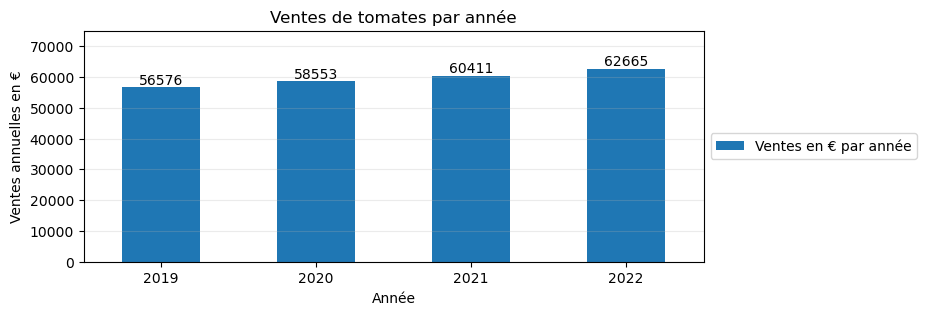

In [32]:
## Graphique barres des ventes par produit et par année
df_tomate_year = df_year_graph[df_year_graph['product'] == 'tomate']
ax = df_tomate_year.plot.bar( x='year', y='sales_year',figsize=(8,3))
ax.bar_label(ax.containers[0]) 
plt.ylim(0, 75000)
plt.legend(labels = ['Ventes en € par année'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes de tomates par année')
plt.xlabel('Année')
ax.tick_params(axis='x', labelrotation=0)
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

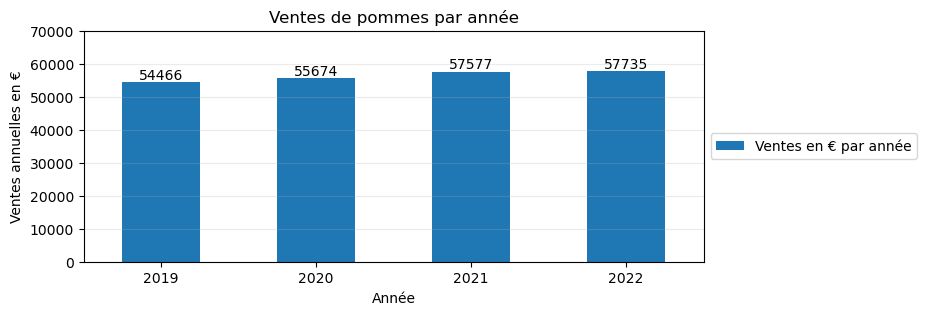

In [33]:
## Graphique barres des ventes par produit et par année
df_pomme_year = df_year_graph[df_year_graph['product'] == 'pomme']
ax = df_pomme_year.plot.bar( x='year', y='sales_year',figsize=(8,3))
ax.bar_label(ax.containers[0]) 
plt.ylim(0, 70000)
plt.legend(labels = ['Ventes en € par année'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes de pommes par année')
plt.xlabel('Année')
ax.tick_params(axis='x', labelrotation=0)
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

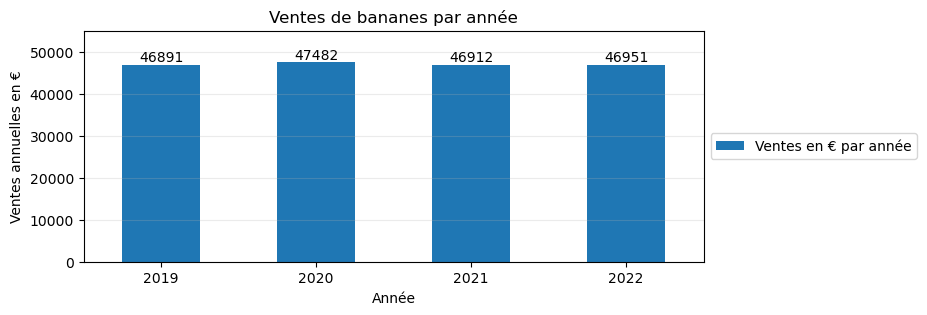

In [34]:
## Graphique barres des ventes par produit et par année
df_banane_year = df_year_graph[df_year_graph['product'] == 'banane']
ax = df_banane_year.plot.bar( x='year', y='sales_year',figsize=(8,3))
ax.bar_label(ax.containers[0]) 
plt.ylim(0, 55000)
plt.legend(labels = ['Ventes en € par année'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes de bananes par année')
plt.xlabel('Année')
ax.tick_params(axis='x', labelrotation=0)
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

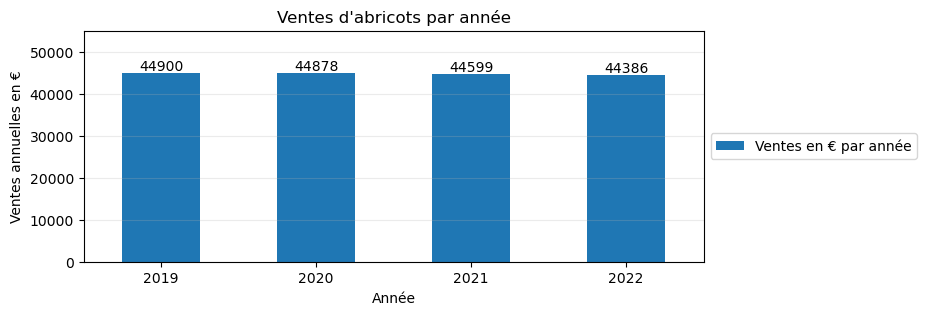

In [35]:
## Graphique barres des ventes par produit et par année
df_abricot_year = df_year_graph[df_year_graph['product'] == 'abricot']
ax = df_abricot_year.plot.bar( x='year', y='sales_year',figsize=(8,3))
ax.bar_label(ax.containers[0]) 
plt.ylim(0, 55000)
plt.legend(labels = ['Ventes en € par année'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes d\'abricots par année')
plt.xlabel('Année')
ax.tick_params(axis='x', labelrotation=0)
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

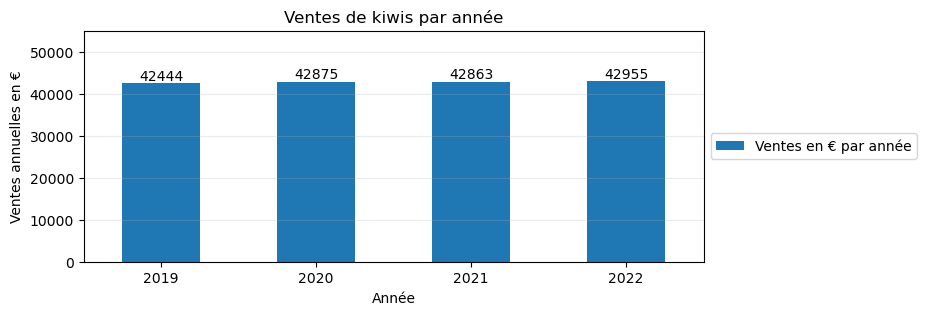

In [36]:
## Graphique barres des ventes par produit et par année
df_kiwi_year = df_year_graph[df_year_graph['product'] == 'kiwi']
ax = df_kiwi_year.plot.bar( x='year', y='sales_year',figsize=(8,3))
ax.bar_label(ax.containers[0]) 
plt.ylim(0, 55000)
plt.legend(labels = ['Ventes en € par année'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes de kiwis par année')
plt.xlabel('Année')
ax.tick_params(axis='x', labelrotation=0)
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

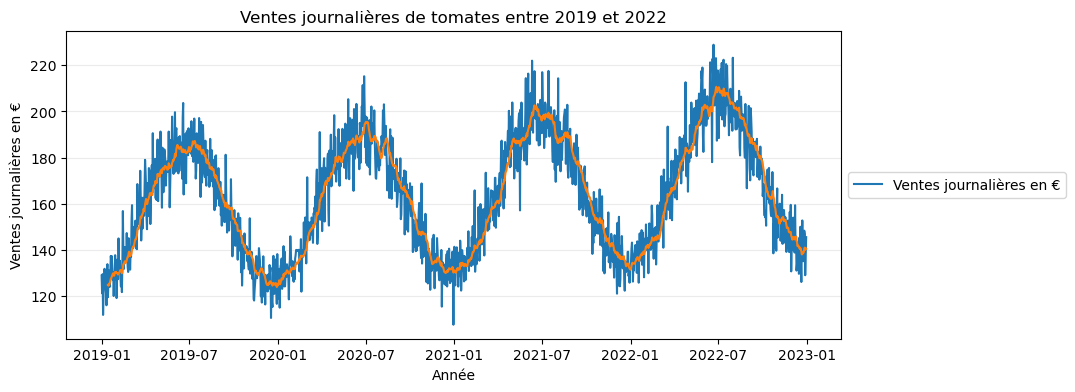

In [37]:
# Graphique des ventes journalières de tomates entre 2019 et 2022
df_tomate = df[df['product'] == 'tomate']
plt.figure(figsize=(10, 4))
plt.plot( df_tomate['date'],df_tomate['sales'])
plt.plot( df_tomate['date'],df_tomate['rolling_sales_14'])
#plt.ylim(0, 250)
plt.legend(labels = ['Ventes journalières en €'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes journalières de tomates entre 2019 et 2022')
plt.xlabel('Année')
plt.ylabel('Ventes journalières en €')
plt.grid(axis='y', alpha=0.25)

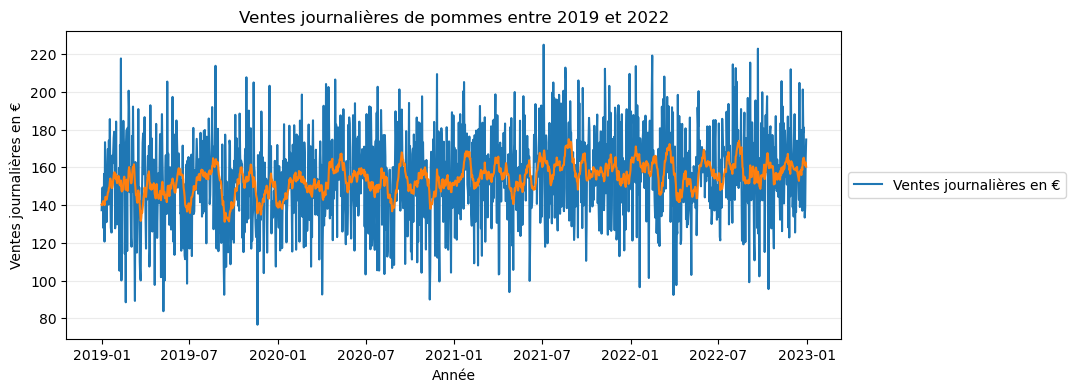

In [38]:
# Graphique des ventes journalières de pommes entre 2019 et 2022
df_pomme = df[df['product'] == 'pomme']
plt.figure(figsize=(10, 4))
plt.plot( df_pomme['date'],df_pomme['sales'])
plt.plot( df_pomme['date'],df_pomme['rolling_sales_14'])
#plt.ylim(0, 250)
plt.legend(labels = ['Ventes journalières en €'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes journalières de pommes entre 2019 et 2022')
plt.xlabel('Année')
plt.ylabel('Ventes journalières en €')
plt.grid(axis='y', alpha=0.25)

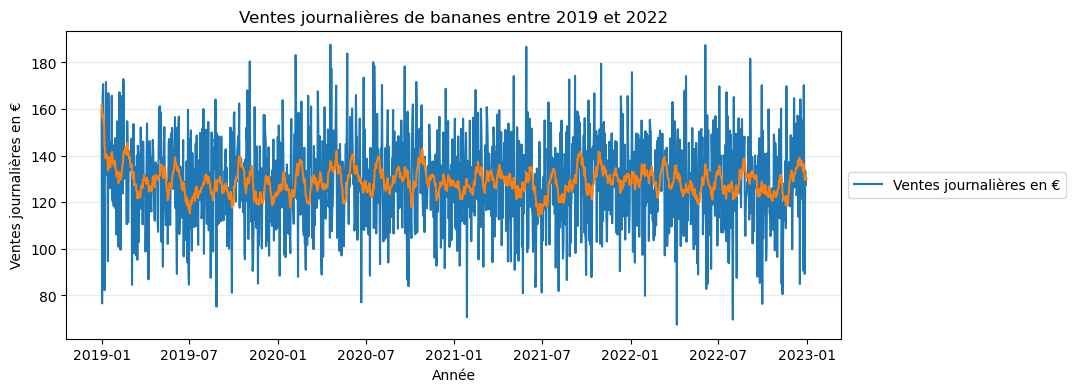

In [39]:
# Graphique des ventes journalières de bananes entre 2019 et 2022
df_banane = df[df['product'] == 'banane']
plt.figure(figsize=(10, 4))
plt.plot( df_banane['date'],df_banane['sales'])
plt.plot( df_banane['date'],df_banane['rolling_sales_14'])
#plt.ylim(0, 250)
plt.legend(labels = ['Ventes journalières en €'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes journalières de bananes entre 2019 et 2022')
plt.xlabel('Année')
plt.ylabel('Ventes journalières en €')
plt.grid(axis='y', alpha=0.25)

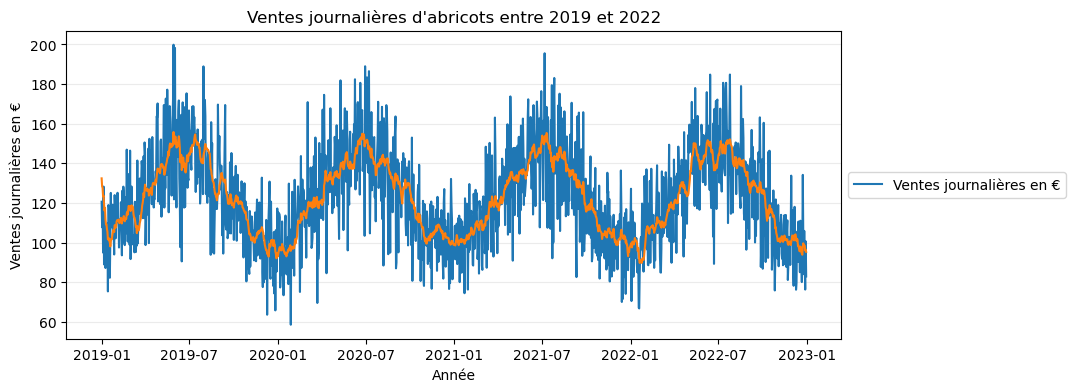

In [40]:
# Graphique des ventes journalières d'abricots entre 2019 et 2022
df_abricot = df[df['product'] == 'abricot']
plt.figure(figsize=(10, 4))
plt.plot( df_abricot['date'],df_abricot['sales'])
plt.plot( df_abricot['date'],df_abricot['rolling_sales_14'])
#plt.ylim(0, 250)
plt.legend(labels = ['Ventes journalières en €'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes journalières d\'abricots entre 2019 et 2022')
plt.xlabel('Année')
plt.ylabel('Ventes journalières en €')
plt.grid(axis='y', alpha=0.25)

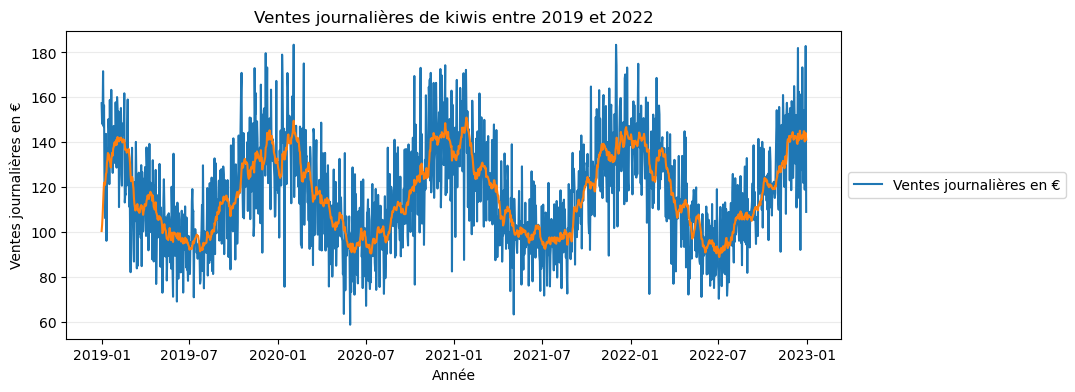

In [41]:
# Graphique des ventes journalières de kiwis entre 2019 et 2022
df_kiwi = df[df['product'] == 'kiwi']
plt.figure(figsize=(10, 4))
plt.plot( df_kiwi['date'],df_kiwi['sales'])
plt.plot( df_kiwi['date'],df_kiwi['rolling_sales_14'])
#plt.ylim(0, 250)
plt.legend(labels = ['Ventes journalières en €'],loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Ventes journalières de kiwis entre 2019 et 2022')
plt.xlabel('Année')
plt.ylabel('Ventes journalières en €')
plt.grid(axis='y', alpha=0.25)

In [42]:
## préparation régression lineaire
df_year_graph_abricot = df_year_graph[df_year_graph['product'] == 'abricot']
df_year_graph_abricot['index'] = df_year_graph_abricot.index + 1
df_year_graph_abricot = df_year_graph_abricot[['index','sales_year']]
df_year_graph_banane = df_year_graph[df_year_graph['product'] == 'banane']
df_year_graph_banane['index'] = df_year_graph_banane.index + 1
df_year_graph_banane = df_year_graph_banane[['index','sales_year']]
df_year_graph_kiwi = df_year_graph[df_year_graph['product'] == 'kiwi']
df_year_graph_kiwi['index'] = df_year_graph_kiwi.index + 1
df_year_graph_kiwi = df_year_graph_kiwi[['index','sales_year']]
df_year_graph_pomme = df_year_graph[df_year_graph['product'] == 'pomme']
df_year_graph_pomme['index'] = df_year_graph_pomme.index + 1
df_year_graph_pomme = df_year_graph_pomme[['index','sales_year']]
df_year_graph_tomate = df_year_graph[df_year_graph['product'] == 'tomate']
df_year_graph_tomate['index'] = df_year_graph_tomate.index + 1
df_year_graph_tomate = df_year_graph_tomate[['index','sales_year']]

C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\1353600962.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_year_graph_abricot['index'] = df_year_graph_abricot.index + 1
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\1353600962.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_year_graph_banane['index'] = df_year_graph_banane.index + 1
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\1353600962.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try usin

In [43]:
# calcul droite regression linéaire
x = df_year_graph_abricot['index']
y = df_year_graph_abricot['sales_year']
slope_abricot, intercept_abricot, r_abricot, p_abricot, std_err_abricot = stats.linregress(x, y)
x = df_year_graph_banane['index']
y = df_year_graph_banane['sales_year']
slope_banane, intercept_banane, r_banane, p_banane, std_err_banane = stats.linregress(x, y)
x = df_year_graph_kiwi['index']
y = df_year_graph_kiwi['sales_year']
slope_kiwi, intercept_kiwi, r_kiwi, p_kiwi, std_err_kiwi = stats.linregress(x, y)
x = df_year_graph_pomme['index']
y = df_year_graph_pomme['sales_year']
slope_pomme, intercept_pomme, r_pomme, p_pomme, std_err_pomme = stats.linregress(x, y)
x = df_year_graph_tomate['index']
y = df_year_graph_tomate['sales_year']
slope_tomate, intercept_tomate, r_tomate, p_tomate, std_err_tomate = stats.linregress(x, y)

In [44]:
print("équation régression linéaire produit abricot: " + slope_abricot.astype(str) + "x + " + intercept_abricot.astype(str))
print("équation régression linéaire produit banane: " + slope_banane.astype(str) + "x + " + intercept_banane.astype(str))
print("équation régression linéaire produit kiwi: " + slope_kiwi.astype(str) + "x + " + intercept_kiwi.astype(str))
print("équation régression linéaire produit pomme: " + slope_pomme.astype(str) + "x + " + intercept_pomme.astype(str))
print("équation régression linéaire produit tomate: " + slope_tomate.astype(str) + "x + " + intercept_tomate.astype(str))

équation régression linéaire produit abricot: -182.1x + 47331.2
équation régression linéaire produit banane: -39.0x + 47468.5
équation régression linéaire produit kiwi: 152.1x + 39970.4
équation régression linéaire produit pomme: 1171.0x + 48751.5
équation régression linéaire produit tomate: 2012.5x + 54520.0


In [45]:
## l'étude des équations des régressions linéaire des ventes annuelles nous indiquent les évolutions des ventes des produits :
## abricot : légère évolution négative des ventes
## banane : stabilité des ventes
## kiwi : légère évolution positive des ventes
## pomme : forte évolution positive des ventes
## tomate : forte évolution positive des ventes

In [46]:
## tableau de calcul des évolutions annuelles des ventes des produits du top 5

table_top5_evol = table_year_pct
table_top5_evol = table_top5_evol[['product',2019,2020,2021,2022]]
table_top5_evol['evolution_2020'] = table_top5_evol.iloc[:, 2] / table_top5_evol.iloc[:, 1] - 1
table_top5_evol['evolution_2021'] = table_top5_evol.iloc[:, 3] / table_top5_evol.iloc[:, 2] - 1
table_top5_evol['evolution_2022'] = table_top5_evol.iloc[:, 4] / table_top5_evol.iloc[:, 3] - 1
table_top5_evol['evolution_totale'] = table_top5_evol.iloc[:, 4] / table_top5_evol.iloc[:, 1] - 1
table_top5_evol['evolution_2020'] = table_top5_evol['evolution_2020'].round(3)
table_top5_evol['evolution_2021'] = table_top5_evol['evolution_2021'].round(3)
table_top5_evol['evolution_2022'] = table_top5_evol['evolution_2022'].round(3)
table_top5_evol['evolution_totale'] = table_top5_evol['evolution_totale'].round(3)
table_top5_evol["rang_evol_2020"] = table_top5_evol['evolution_2020'].rank(ascending=False)
table_top5_evol["rang_evol_2021"] = table_top5_evol['evolution_2021'].rank(ascending=False)
table_top5_evol["rang_evol_2022"] = table_top5_evol['evolution_2022'].rank(ascending=False)
table_top5_evol["rang_evol_totale"] = table_top5_evol['evolution_totale'].rank(ascending=False)
table_top5_evol = table_top5_evol.sort_values(by=['rang_evol_totale'])
table_top5_evol

C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\204287985.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  table_top5_evol['evolution_2020'] = table_top5_evol.iloc[:, 2] / table_top5_evol.iloc[:, 1] - 1
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\204287985.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  table_top5_evol['evolution_2021'] = table_top5_evol.iloc[:, 3] / table_top5_evol.iloc[:, 2] - 1
C:\Users\Ced\AppData\Local\Temp\ipykernel_9744\204287985.py:7: SettingWithCopyWarning: 
A value is try

year,product,2019,2020,2021,2022,evolution_2020,evolution_2021,evolution_2022,evolution_totale,rang_evol_2020,rang_evol_2021,rang_evol_2022,rang_evol_totale
0,tomate,56582.0,58560.0,60400.0,62666.0,0.035,0.031,0.038,0.108,1.0,2.0,1.0,1.0
1,pomme,54462.0,55671.0,57579.0,57727.0,0.022,0.034,0.003,0.060,2.0,1.0,2.0,2.0
4,kiwi,42441.0,42870.0,42864.0,42945.0,0.010,-0.000,0.002,0.012,4.0,3.0,3.0,3.0
2,banane,46903.0,47496.0,46911.0,46951.0,0.013,-0.012,0.001,0.001,3.0,5.0,4.0,4.0
3,abricot,44898.0,44881.0,44589.0,44393.0,-0.000,-0.007,-0.004,-0.011,5.0,4.0,5.0,5.0


In [47]:
## le tableau comparatif des évolutions des ventes nous confirme les évolutions suivantes sur les ventes des produits
## tomate : forte évolution positive des ventes
## pomme : forte évolution positive des ventes
## kiwi : légère évolution positive des ventes
## banane : stabilité des ventes
## abricot : légère évolution négative des ventes

In [48]:
##
##
# ETAPE 3 - Analysez comparativement les volumes commandés pour les différents produits du Top 5
# Graphique en ligne comparatif des ventes annuelles par produit
# Tableau des pourcentages de ventes par mois par produit et rangs mensuels
# Graphique en ligne comparatif des ventes mensuelles par produit
##
##

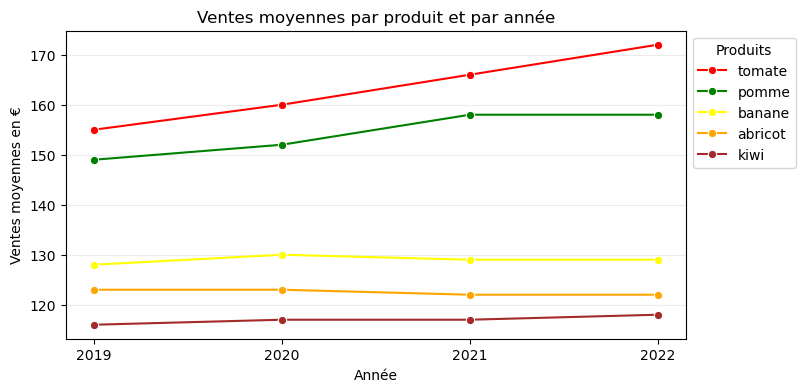

In [49]:
## Graphique comparatif des ventes par produits et par année
fig = plt.subplots(figsize=(8, 4))
sns.lineplot(x="year", y="sales_year_mean", hue="product",marker="o", data=df_year_graph,palette=['red', 'green', 'yellow', 'orange', 'brown'])
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Produits")
plt.title('Ventes moyennes par produit et par année')
plt.xlabel('Année')
plt.xticks([2019,2020,2021,2022])
plt.ylabel('Ventes moyennes en €')
plt.grid(axis='y', alpha=0.25)

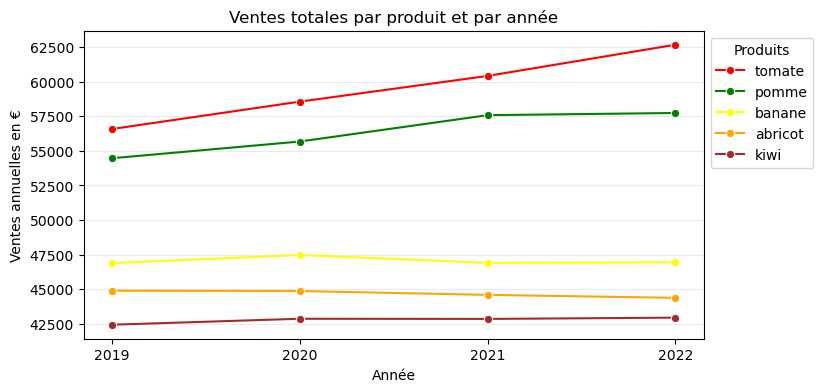

In [50]:
## Graphique comparatif des ventes par produits et par année
fig = plt.subplots(figsize=(8, 4))
sns.lineplot(x="year", y="sales_year", hue="product",marker="o", data=df_year_graph, palette=['red', 'green', 'yellow', 'orange', 'brown'])
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Produits")
plt.title('Ventes totales par produit et par année')
plt.xlabel('Année')
plt.xticks([2019,2020,2021,2022])
plt.ylabel('Ventes annuelles en €')
plt.grid(axis='y', alpha=0.25)

In [51]:
## Les ventes de tomates et de pommes sont nettement supérieures aux trois autres produits et en forte évolution
## Les ventes de bananes, abricots, kiwis, se situent au même niveau (entre 42000 et 47000) et sont plus stables

In [52]:
## Création tableau de données des ventes mensuelles
df_months_graph = df_year[['product','year','quarter','month','year_month','sales_quarter','sales_month']]
df_months_graph = df_months_graph[ df_months_graph['product'].isin(list_product_top5)]
df_months_graph = df_months_graph.drop_duplicates()
df_months_graph = df_months_graph.reset_index(drop=True)
df_months_graph['total_year'] = df_months_graph.groupby(['product','year'])['sales_month'].transform('sum')
df_months_graph['total_quarter'] = df_months_graph.groupby(['product','quarter'])['sales_quarter'].transform('sum')
df_months_graph['quarter_ratio'] = df_months_graph['sales_quarter'] / df_months_graph['total_year']
df_months_graph['quarter_ratio'] = df_months_graph['quarter_ratio'].round(4)
df_months_graph['month_ratio'] = df_months_graph['sales_month'] / df_months_graph['total_year']
df_months_graph['month_ratio'] = df_months_graph['month_ratio'].round(4)
#df_months_graph

In [53]:
## tableau de poids des ventes mensuelles par rapport au total annuel
table_month_season = pd.pivot_table(df_months_graph, values='month_ratio', index='month', columns='product', aggfunc='mean')
table_month_season = table_month_season.reset_index()
table_month_season = table_month_season.round(5)
table_month_season["abricot"] = table_month_season['abricot'] *100
table_month_season["banane"] = table_month_season['banane'] *100
table_month_season["kiwi"] = table_month_season['kiwi'] *100
table_month_season["pomme"] = table_month_season['pomme'] *100
table_month_season["tomate"] = table_month_season['tomate'] *100
table_month_season["rang_mois_abricot"] = table_month_season['abricot'].rank(ascending=False)
table_month_season["rang_mois_banane"] = table_month_season['banane'].rank(ascending=False)
table_month_season["rang_mois_kiwi"] = table_month_season['kiwi'].rank(ascending=False)
table_month_season["rang_mois_pomme"] = table_month_season['pomme'].rank(ascending=False)
table_month_season["rang_mois_tomate"] = table_month_season['tomate'].rank(ascending=False)
table_month_season = table_month_season.rename(columns={'month': 'mois'})
table_month_season = table_month_season.rename(index={0: "Janvier", 1: "Fevrier", 2: "Mars", 3: "Avril", 4: "Mai", 5: "Juin", 6: "Juillet", 7: "Aout", 8: "Septembre", 9: "Octobre", 10: "Novembre", 11: "Decembre"})
table_month_season

product,mois,abricot,banane,kiwi,pomme,tomate,rang_mois_abricot,rang_mois_banane,rang_mois_kiwi,rang_mois_pomme,rang_mois_tomate
Janvier,1,6.975,8.535,10.138,8.540,6.898,10.0,3.0,2.0,3.0,11.0
Fevrier,2,6.992,7.920,8.685,7.738,6.648,9.0,12.0,5.0,12.0,12.0
Mars,3,8.168,8.570,8.508,8.490,8.188,7.0,2.0,6.0,5.0,7.0
Avril,4,8.755,8.242,7.658,8.025,8.825,5.0,8.0,8.0,11.0,5.0
Mai,5,9.760,8.482,7.145,8.478,9.682,3.0,4.0,10.0,6.0,3.0
Juin,6,9.838,8.050,6.728,8.218,9.800,2.0,11.0,12.0,8.0,2.0
Juillet,7,10.100,8.372,6.968,8.512,10.008,1.0,7.0,11.0,4.0,1.0
Aout,8,9.455,8.410,7.475,8.732,9.582,4.0,6.0,9.0,1.0,4.0
Septembre,9,8.435,8.232,7.988,8.075,8.522,6.0,9.0,7.0,10.0,6.0
Octobre,10,7.738,8.605,9.025,8.622,7.892,8.0,1.0,4.0,2.0,8.0


In [54]:
## Les coefficients saisonniers sont différents selon les produits mais il existe quelques similitudes entre les ventes de tomates et d'abricots.

([<matplotlib.axis.XTick at 0x16670b54190>,
 [Text(0.0, 0, '2019-1'),
  Text(12.0, 0, '2020-1'),
  Text(24.0, 0, '2021-1'),
  Text(36.0, 0, '2022-1')])

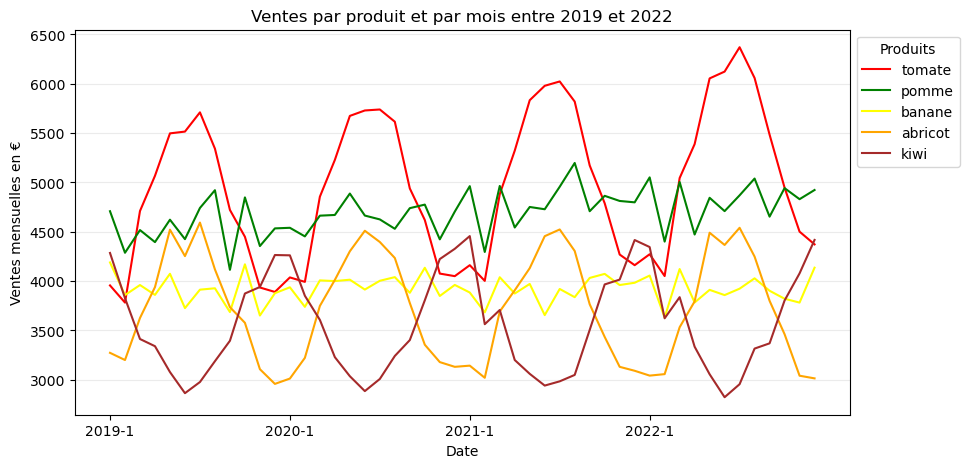

In [55]:
# Graphique comparatif des ventes par produit et par mois
fig = plt.subplots(figsize=(10, 5))
my_plot = sns.lineplot(x="year_month", y="sales_month",hue="product",data=df_months_graph,palette=['red', 'green', 'yellow', 'orange', 'brown'])
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Produits")
plt.title('Ventes par produit et par mois entre 2019 et 2022')
plt.xlabel('Date')
plt.ylabel('Ventes mensuelles en €')
plt.grid(axis='y', alpha=0.25)
labels = ['2019-1', '2020-1', '2021-1', '2022-1']
plt.xticks(labels, rotation='horizontal')

In [56]:
## Commentaires

## Les ventes de tomates et d'abricots connaissent un pic de vente en milieu d'année et un creux en fin d'année
## Ce sont des produits avec une saisonnalité estivale

## Les ventes de kiwi connaissent un pic de vente en fin d'année et un creux en milieu d'année
## C'est un produit avec une saisonnalité hivernale

## Les ventes de pommes et de bananes n'ont pas de pic de vente identifiable
## Ce sont des produits sans saisonnalité marquée

In [57]:
##
##
# ETAPE 4 - proposez une répartition optimale de stock dans l'entrepôt  
# Graphique en ligne comparatif des ventes mensuelles moyennes par produit et par identifiant mois
# Carte thermique des rangs mensuels des ventes par mois et par produit
# Matrice de corrélation des ventes des produits du top 5
# Graphiques de distribution des données de ventes des produits du top 5
# Tests de normalité des séries statistiques de ventes
# Calculs de corrélation et représentations graphiques
##
##

In [58]:
## Tableau des ventes par produit et identifiant mois

df_month_graph = df_year[['product','month','sales_month']]
df_month_graph = df_month_graph[ df_month_graph['product'].isin(list_product_top5)]
df_month_graph = df_month_graph.drop_duplicates()
df_month_graph = df_month_graph.reset_index(drop=True)
#df_month_graph

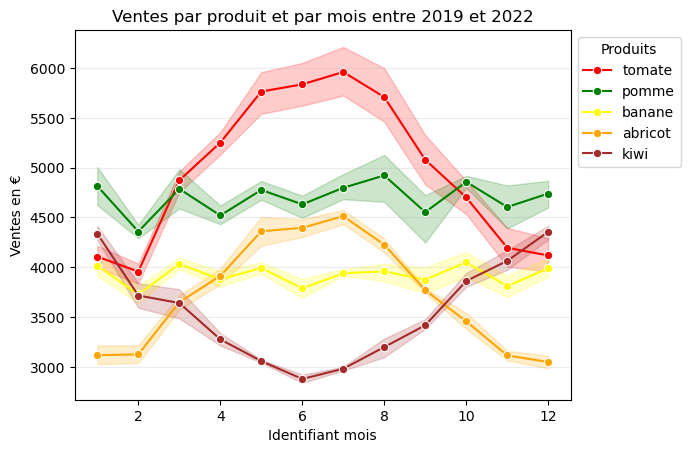

In [59]:
## Graphique comparatif des ventes par produit et identifiant mois
sns.lineplot(x="month", y="sales_month",hue="product",marker="o",data=df_month_graph,palette=['red', 'green', 'yellow', 'orange', 'brown'])
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Produits")
plt.title('Ventes par produit et par mois entre 2019 et 2022')
plt.xlabel('Identifiant mois')
plt.ylabel('Ventes en €')
plt.grid(axis='y', alpha=0.25)

In [60]:
## Les ventes de tomates et d'abricots ont un profil similaire avec des fortes ventes en milieu d'année
## Les ventes de pommes et de bananes ont un profil similaire avec une absence de saisonnalité
## Les ventes de kiwi n'ont pas d'équivalent parmis les produits du Top 5

In [61]:
# Carte graphique des rangs mensuels moyens des ventes des produits
table_month_season_heatmap = table_month_season[['rang_mois_abricot','rang_mois_banane','rang_mois_kiwi','rang_mois_pomme','rang_mois_tomate']]
table_month_season_heatmap = table_month_season_heatmap.astype('int64')
table_month_season_heatmap.style.background_gradient(cmap='Blues')

product,rang_mois_abricot,rang_mois_banane,rang_mois_kiwi,rang_mois_pomme,rang_mois_tomate
Janvier,10,3,2,3,11
Fevrier,9,12,5,12,12
Mars,7,2,6,5,7
Avril,5,8,8,11,5
Mai,3,4,10,6,3
Juin,2,11,12,8,2
Juillet,1,7,11,4,1
Aout,4,6,9,1,4
Septembre,6,9,7,10,6
Octobre,8,1,4,2,8


In [62]:
## Le graphique heatmap des coefficients de saisonnalité mensuels nous confirme les conclusions précédentes
## Les ventes d'abricots et de tomates sont de couleur claire au milieu de l'année en même temps
## Les ventes de kiwi sont de couleur claire en fin d'année
## Les ventes de bananes et de pommes alternes des pics et des creux de vente tout au long de l'année

Text(0.5, 1.0, 'Matrice de corrélation des produits du Top 5')

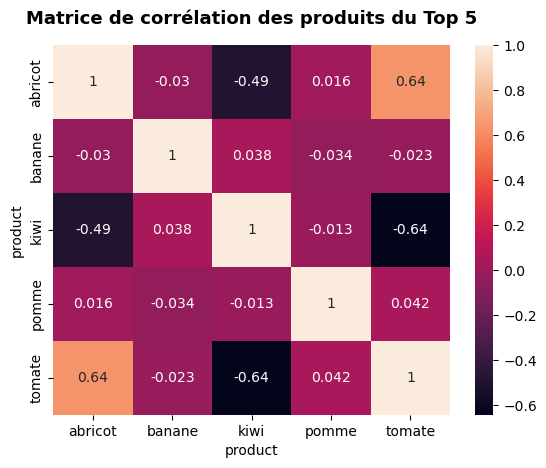

In [63]:
## Matrice de corrélation des données de ventes des produits du top 5

table_correlation = table_product[['abricot','banane','kiwi','pomme','tomate']]
correlation_matrix = table_correlation.corr()
correlation_matrix = correlation_matrix.round(3)
sns.heatmap(correlation_matrix, annot=True)
plt.title("Matrice de corrélation des produits du Top 5", fontsize = 13, weight='bold', pad=15, loc = 'center')

In [64]:
## Nous pouvons observer une corrélation entre deux produits
## Il y a une corrélation de 0,64 entre les ventes d'abricots et de tomates : c'est une corrélation forte et positive

In [65]:
## Nous procédons à l'étude des distributions des ventes de produits pour pouvoir effectuer des tests statistiques

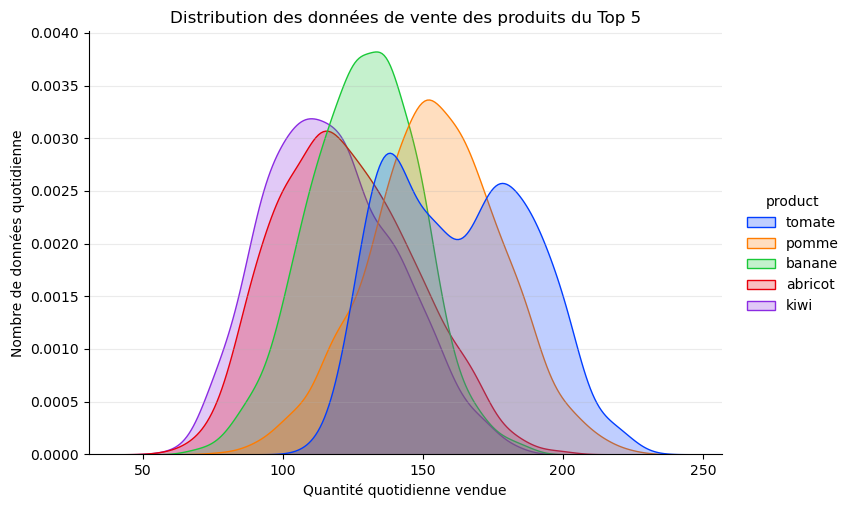

In [66]:
## Graphique comparatif des distributions des séries de données de vente

sns.displot(data = df_year_top5, x='sales', hue='product', kind='kde', fill=True, palette=sns.color_palette('bright')[:5], height=5, aspect=1.5)
plt.title('Distribution des données de vente des produits du Top 5')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

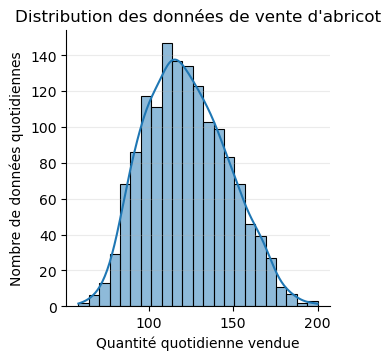

In [100]:
## Graphique distribution des données
sns.displot(x="abricot", kde=True,data=table_product, height=3.5)
plt.title('Distribution des données de vente d\'abricot')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

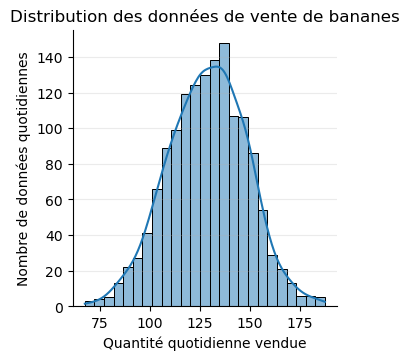

In [101]:
## Graphique distribution des données
sns.displot(x="banane", kde=True,data=table_product, height=3.5)
plt.title('Distribution des données de vente de bananes')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

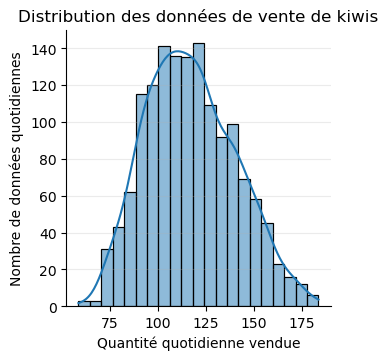

In [102]:
## Graphique distribution des données
sns.displot(x="kiwi", kde=True,data=table_product, height=3.5)
plt.title('Distribution des données de vente de kiwis')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

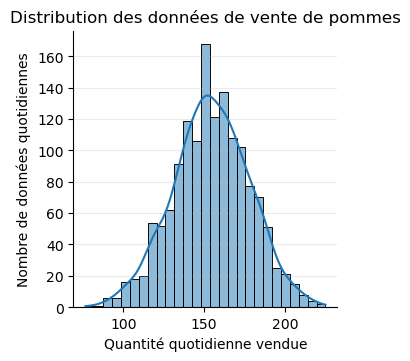

In [103]:
## Graphique distribution des données
sns.displot(x="pomme", kde=True,data=table_product, height=3.5)
plt.title('Distribution des données de vente de pommes')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

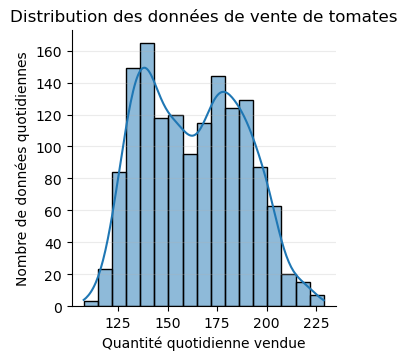

In [104]:
## Graphique distribution des données
sns.displot(x="tomate", kde=True,data=table_product, height=3.5)
plt.title('Distribution des données de vente de tomates')
plt.xlabel('Quantité quotidienne vendue')
plt.ylabel('Nombre de données quotidiennes')
plt.grid(axis='y', alpha=0.25)

In [105]:
## Nous procédons à des tests de normalité des ventes de produits pour pouvoir effectuer des tests statistiques

In [106]:
ventes = table_product['abricot'].dropna()
stat, p_value = shapiro(ventes)
print('Test Shapiro-Wilk produit abricot:', round(stat,3))
print('Valeur p produit abricot:', round(p_value,4))
alpha = 0.05
if p_value > alpha:
    print("Distribution normale")
else:
    print("Distribution non normale")

Test Shapiro-Wilk produit abricot: 0.99
Valeur p produit abricot: 0.0
Distribution non normale


In [107]:
ventes = table_product['banane'].dropna()
stat, p_value = shapiro(ventes)
print('Test Shapiro-Wilk produit banane:', round(stat,3))
print('Valeur p produit banane:', round(p_value,4))
alpha = 0.05
if p_value > alpha:
    print("Distribution normale")
else:
    print("Distribution non normale")

Test Shapiro-Wilk produit banane: 0.999
Valeur p produit banane: 0.3162
Distribution normale


In [108]:
ventes = table_product['kiwi'].dropna()
stat, p_value = shapiro(ventes)
print('Test Shapiro-Wilk produit kiwi:', round(stat,3))
print('Valeur p produit kiwi:', round(p_value,4))
alpha = 0.05
if p_value > alpha:
    print("Distribution normale")
else:
    print("Distribution non normale")

Test Shapiro-Wilk produit kiwi: 0.989
Valeur p produit kiwi: 0.0
Distribution non normale


In [109]:
ventes = table_product['pomme'].dropna()
stat, p_value = shapiro(ventes)
print('Test Shapiro-Wilk produit pomme:', round(stat,3))
print('Valeur p produit pomme:', round(p_value,4))
alpha = 0.05
if p_value > alpha:
    print("Distribution normale")
else:
    print("Distribution non normale")

Test Shapiro-Wilk produit pomme: 0.999
Valeur p produit pomme: 0.6776
Distribution normale


In [110]:
ventes = table_product['tomate'].dropna()
stat, p_value = shapiro(ventes)
print('Test Shapiro-Wilk produit tomate:', round(stat,3))
print('Valeur p produit tomate:', round(p_value,4))
alpha = 0.05
if p_value > alpha:
    print("Distribution normale")
else:
    print("Distribution non normale")

Test Shapiro-Wilk produit tomate: 0.97
Valeur p produit tomate: 0.0
Distribution non normale


Coefficient de corrélation de Pearson: 0.648
Valeur p: 0.0
Il y a une corrélation entre les ventes de tomates et d'abricots


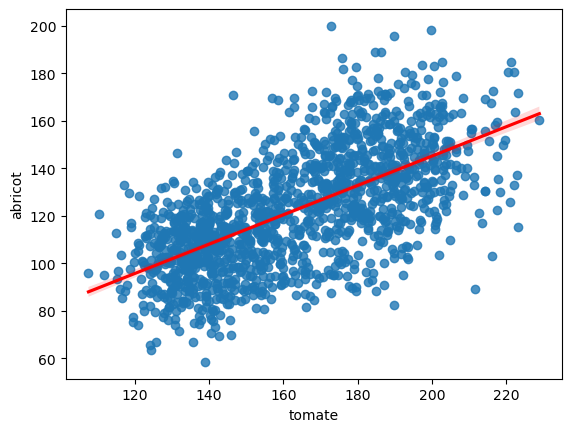

In [111]:
## Graphique nuage de points entre les ventes de tomates et d'abricots
tomate = table_product['tomate']
abricot = table_product['abricot']
sns.regplot(x=tomate, y=abricot, robust=True, line_kws=dict(color="r"))
correlation, p_value = spearmanr(tomate, abricot)
print('Coefficient de corrélation de Pearson:', round(correlation,3))
print('Valeur p:', round(p_value,3))
print('Il y a une corrélation positive entre les ventes de tomates et d\'abricots')

Coefficient de corrélation de Pearson: -0.655
Valeur p: 0.0
Il y a une corrélation entre les ventes de tomates et d'abricots


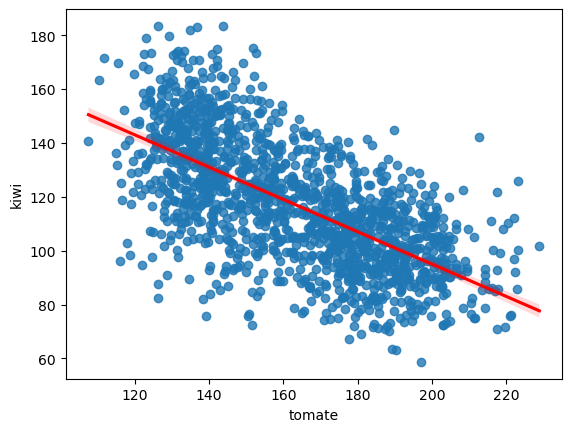

In [113]:
## Graphique nuage de points entre les ventes de tomates et de kiwis
tomate = table_product['tomate']
kiwi = table_product['kiwi']
sns.regplot(x=tomate, y=kiwi, robust=True, line_kws=dict(color="r"))
correlation, p_value = spearmanr(tomate, kiwi)
print('Coefficient de corrélation de Pearson:', round(correlation,3))
print('Valeur p:', round(p_value,3))
print('Il y a une corrélation négative entre les ventes de tomates et dr kiwis')

Coefficient de corrélation de Pearson: -0.034
Valeur p: 0.199
Il n'y a pas de corrélation entre les ventes de bananes et de pommes


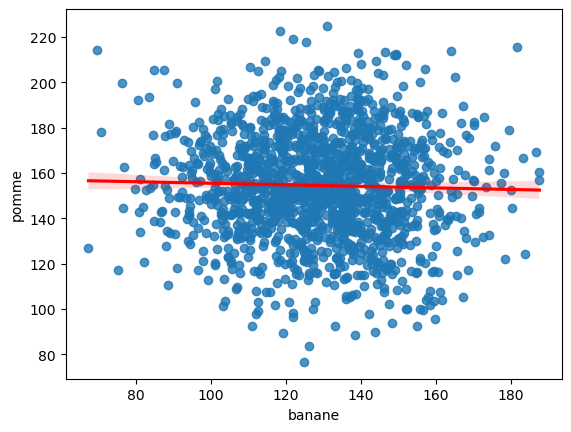

In [112]:
## Graphique nuage de points entre les ventes de tomates et d'abricots
tomate = table_product['banane']
abricot = table_product['pomme']
sns.regplot(x=tomate, y=abricot, robust=True, line_kws=dict(color="r"))
correlation, p_value = pearsonr(tomate, abricot)
print('Coefficient de corrélation de Pearson:', round(correlation,3))
print('Valeur p:', round(p_value,3))
print('Il n\'y a pas de corrélation entre les ventes de bananes et de pommes')

In [80]:
##
## Recommandations
##

In [81]:
## En prenant en compte les résultats des études statistiques, nous pouvons déterminer qu'il faut regrouper
## les produits tomates et abricots dans l'entrepôt en raison de la forte corrélation des ventes de ces deux produits

## Il n'y a pas de corrélation statistique entre les ventes de bananes et de pommes
## Néanmoins, il serait préférable de les regrouper dans l'entrepôt en raison d'un profil
## similaire de ventes sans saisonnalité marquée avec des ventes constantes tout au long de l'année

## Le produit kiwi n'a pas de corrélation de ventes avec d'autres produits

In [82]:
##
## Prévisions des ventes de l'année suivante
##

In [83]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

In [84]:
df_monthly_abricot = df_months_graph[df_months_graph['product'] == 'abricot']
df_monthly_banane = df_months_graph[df_months_graph['product'] == 'banane']
df_monthly_kiwi = df_months_graph[df_months_graph['product'] == 'kiwi']
df_monthly_pomme = df_months_graph[df_months_graph['product'] == 'pomme']
df_monthly_tomate = df_months_graph[df_months_graph['product'] == 'tomate']
df_monthly_abricot = df_monthly_abricot.reset_index(drop=True)
df_monthly_banane = df_monthly_banane.reset_index(drop=True)
df_monthly_kiwi = df_monthly_kiwi.reset_index(drop=True)
df_monthly_pomme = df_monthly_pomme.reset_index(drop=True)
df_monthly_tomate = df_monthly_tomate.reset_index(drop=True)

In [85]:
monthly_sales_abricot = df_monthly_abricot['sales_month']
monthly_sales_banane = df_monthly_banane['sales_month']
monthly_sales_kiwi = df_monthly_kiwi['sales_month']
monthly_sales_pomme = df_monthly_pomme['sales_month']
monthly_sales_tomate = df_monthly_tomate['sales_month']

In [86]:
df_sales_1 = pd.concat([monthly_sales_abricot,monthly_sales_banane], axis=1)
df_sales_2 = pd.concat([df_sales_1,monthly_sales_kiwi], axis=1)
df_sales_3 = pd.concat([df_sales_2,monthly_sales_pomme], axis=1)
df_sales = pd.concat([df_sales_3,monthly_sales_tomate], axis=1)
#df_sales

In [87]:
def rename_col_by_index(dataframe, index_mapping):
    dataframe.columns = [index_mapping.get(i, col) for i, col in enumerate(dataframe.columns)]
    return dataframe

In [88]:
new_column_mapping = {0: 'abricot', 1: 'banane', 2: 'kiwi', 3: 'pomme', 4: 'tomate'}
df_sales = rename_col_by_index(df_sales, new_column_mapping)
#df_sales

In [89]:
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12
model = SARIMAX(monthly_sales_abricot, order=(p, d, q), seasonal_order=(P, D, Q, s))
results_abricot = model.fit()

C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [90]:
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12
model = SARIMAX(monthly_sales_banane, order=(p, d, q), seasonal_order=(P, D, Q, s))
results_banane = model.fit()

C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [91]:
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12
model = SARIMAX(monthly_sales_kiwi, order=(p, d, q), seasonal_order=(P, D, Q, s))
results_kiwi = model.fit()

C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [92]:
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12
model = SARIMAX(monthly_sales_pomme, order=(p, d, q), seasonal_order=(P, D, Q, s))
results_pomme = model.fit()

C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [93]:
p, d, q = 1, 1, 1
P, D, Q, s = 1, 1, 1, 12
model = SARIMAX(monthly_sales_tomate, order=(p, d, q), seasonal_order=(P, D, Q, s))
results_tomate = model.fit()

C:\Users\Ced\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


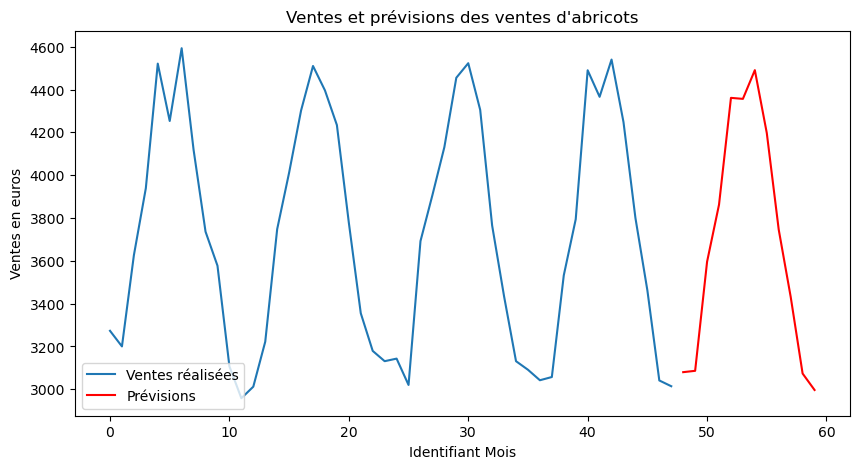

In [94]:
forecast_periods = 12
forecast_abricot = results_abricot.forecast(steps=forecast_periods)
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales_abricot, label='Ventes réalisées')
plt.plot(forecast_abricot, label='Prévisions', color='red')
plt.title("Ventes et prévisions des ventes d'abricots")
plt.xlabel("Identifiant Mois")
plt.ylabel("Ventes en euros")
plt.legend(loc="lower left")
plt.show()

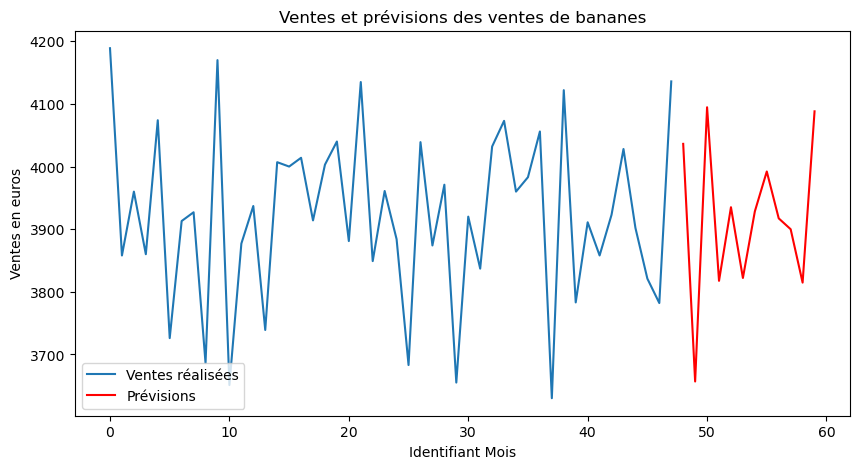

In [95]:
forecast_periods = 12
forecast_banane = results_banane.forecast(steps=forecast_periods)
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales_banane, label='Ventes réalisées')
plt.plot(forecast_banane, label='Prévisions', color='red')
plt.title("Ventes et prévisions des ventes de bananes")
plt.xlabel("Identifiant Mois")
plt.ylabel("Ventes en euros")
plt.legend(loc="lower left")
plt.show()

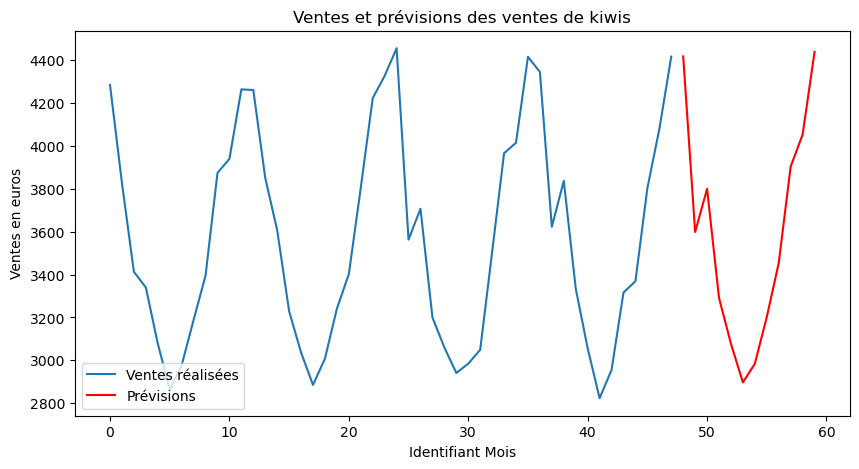

In [96]:
forecast_periods = 12
forecast_kiwi = results_kiwi.forecast(steps=forecast_periods)
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales_kiwi, label='Ventes réalisées')
plt.plot(forecast_kiwi, label='Prévisions', color='red')
plt.title("Ventes et prévisions des ventes de kiwis")
plt.xlabel("Identifiant Mois")
plt.ylabel("Ventes en euros")
plt.legend(loc="lower left")
plt.show()

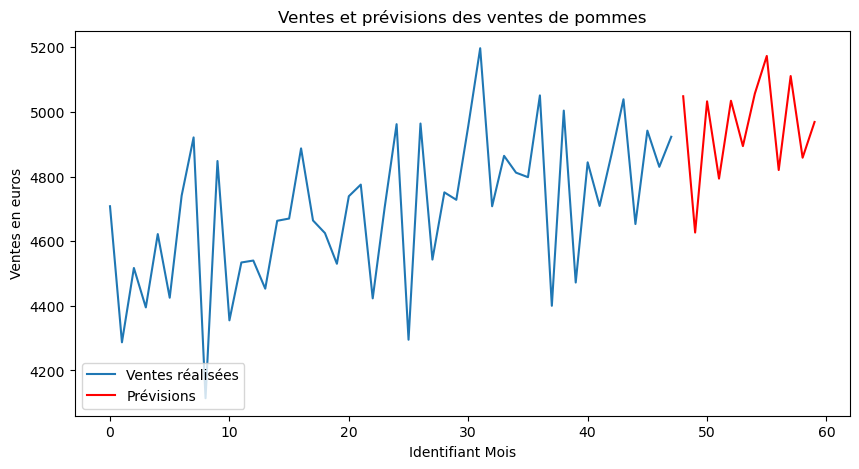

In [97]:
forecast_periods = 12
forecast_pomme = results_pomme.forecast(steps=forecast_periods)
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales_pomme, label='Ventes réalisées')
plt.plot(forecast_pomme, label='Prévisions', color='red')
plt.title("Ventes et prévisions des ventes de pommes")
plt.xlabel("Identifiant Mois")
plt.ylabel("Ventes en euros")
plt.legend(loc="lower left")
plt.show()

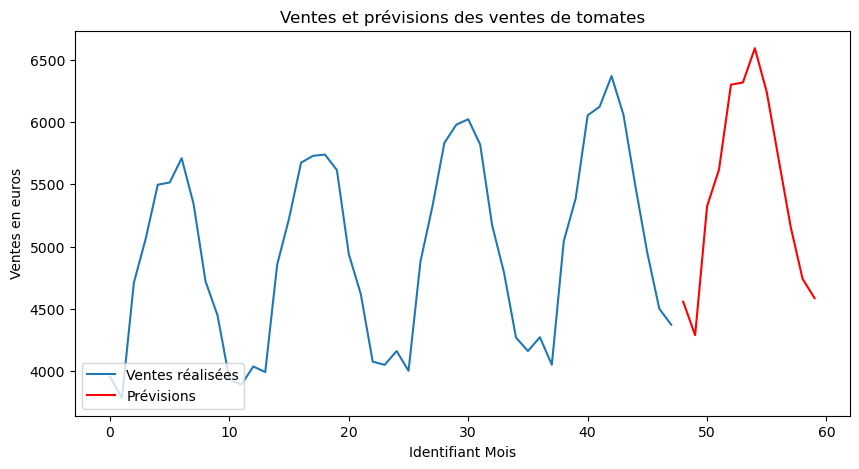

In [98]:
forecast_periods = 12
forecast_tomate = results_tomate.forecast(steps=forecast_periods)
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales_tomate, label='Ventes réalisées')
plt.plot(forecast_tomate, label='Prévisions', color='red')
plt.title("Ventes et prévisions des ventes de tomates")
plt.xlabel("Identifiant Mois")
plt.ylabel("Ventes en euros")
plt.legend(loc="lower left")
plt.show()

In [114]:
# Calcul des indicateurs de précisions en valeur absolue

observed_abricot = monthly_sales_abricot.tail(forecast_periods)
observed_banane = monthly_sales_banane.tail(forecast_periods)
observed_kiwi = monthly_sales_kiwi.tail(forecast_periods)
observed_pomme = monthly_sales_pomme.tail(forecast_periods)
observed_tomate = monthly_sales_tomate.tail(forecast_periods)

mae_abricot = mean_absolute_error(observed_abricot, forecast_abricot)
mape_abricot = mean_absolute_percentage_error(observed_abricot, forecast_abricot)
mae_banane = mean_absolute_error(observed_banane, forecast_banane)
mape_banane = mean_absolute_percentage_error(observed_banane, forecast_banane)
mae_kiwi = mean_absolute_error(observed_kiwi, forecast_kiwi)
mape_kiwi = mean_absolute_percentage_error(observed_kiwi, forecast_kiwi)
mae_pomme= mean_absolute_error(observed_pomme, forecast_pomme)
mape_pomme = mean_absolute_percentage_error(observed_pomme, forecast_pomme)
mae_tomate = mean_absolute_error(observed_tomate, forecast_tomate)
mape_tomate = mean_absolute_percentage_error(observed_tomate, forecast_tomate)

print("MAE_abricot:", round(mae_abricot,3))
print("MAPE_abricot:", round(mape_abricot,3))
print("-----")
print("MAE_banane:", round(mae_banane,3))
print("MAPE_banane:", round(mape_banane,3))
print("-----")
print("MAE_kiwi:", round(mae_kiwi,3))
print("MAPE_kiwi:", round(mape_kiwi,3))
print("-----")
print("MAE_pomme:", round(mae_pomme,3))
print("MAPE_pomme:", round(mape_pomme,3))
print("-----")
print("MAE_tomate:", round(mae_tomate,3))
print("MAPE_tomate:", round(mape_tomate,3))

MAE_abricot: 47.634
MAPE_abricot: 0.013
-----
MAE_banane: 32.007
MAPE_banane: 0.008
-----
MAE_kiwi: 54.032
MAPE_kiwi: 0.016
-----
MAE_pomme: 140.562
MAPE_pomme: 0.03
-----
MAE_tomate: 230.001
MAPE_tomate: 0.045
